In [1]:
# !python -m pip install --upgrade pip

In [2]:
# !pip install --upgrade tree-sitter tree-sitter-c

In [3]:
import os
import json
from pathlib import Path
from collections import defaultdict

# Set GPU before importing torch
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
import torch
import numpy as np
import matplotlib.pyplot as plt
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForCausalLM
from tqdm import tqdm
import random

import pandas as pd
import numpy as np
from datasets import Dataset, DatasetDict, concatenate_datasets, load_from_disk

/usr/local/lib/python3.12/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [5]:
# Tree-sitter imports
import tree_sitter_c as tsc
from tree_sitter import Language, Parser

In [6]:
torch.cuda.empty_cache()

In [7]:
ds = Dataset.from_file("/home/stu354543/exebench_dataset/data-00000-of-00004.arrow")
print(ds)

Dataset({
    features: ['func_name', 'org_function', 'real_io_pairs', 'OPT_level', 'obf_pass', 'p_code_refined_obf', 'raw_obf', 'p_code_obf', 'c_code_obf', 'assembly_obf', 'p_code_refined_unobf', 'raw_unobf', 'p_code_unobf', 'c_code_unobf', 'assembly_unobf'],
    num_rows: 5993
})


In [8]:
NODE_TYPE_GROUPS = {
    # Identifiers
    "identifier": "identifier",
    "field_identifier": "identifier",
    "type_identifier": "type_identifier",
    "sized_type_specifier": "type_identifier",
    # Primitive types
    "primitive_type": "primitive_type",
    # Literals
    "number_literal": "number_literal",
    "string_literal": "string_literal",
    "string_content": "string_literal",
    "char_literal": "char_literal",
    "true": "boolean_literal",
    "false": "boolean_literal",
    "null": "null_literal",
    # Assignment operators
    "=": "assignment_op",
    "+=": "assignment_op",
    "-=": "assignment_op",
    "*=": "assignment_op",
    "/=": "assignment_op",
    "%=": "assignment_op",
    "&=": "assignment_op",
    "|=": "assignment_op",
    "^=": "assignment_op",
    "<<=": "assignment_op",
    ">>=": "assignment_op",
    # Arithmetic operators
    "+": "arithmetic_op",
    "-": "arithmetic_op",
    "*": "arithmetic_op",
    "/": "arithmetic_op",
    "%": "arithmetic_op",
    # Unary operators
    "++": "unary_op",
    "--": "unary_op",
    "!": "unary_op",
    "~": "unary_op",
    # Comparison operators
    "==": "comparison_op",
    "!=": "comparison_op",
    "<": "comparison_op",
    ">": "comparison_op",
    "<=": "comparison_op",
    ">=": "comparison_op",
    # Logical operators
    "&&": "logical_op",
    "||": "logical_op",
    # Bitwise operators
    "&": "bitwise_op",
    "|": "bitwise_op",
    "^": "bitwise_op",
    "<<": "bitwise_op",
    ">>": "bitwise_op",
    # Member access
    "->": "member_access",
    ".": "member_access",
    # Punctuation
    "(": "paren",
    ")": "paren",
    "{": "brace",
    "}": "brace",
    "[": "bracket",
    "]": "bracket",
    ";": "semicolon",
    ",": "comma",
    ":": "colon",
    "?": "ternary",
    # Control flow keywords
    "if": "keyword_control",
    "else": "keyword_control",
    "while": "keyword_control",
    "for": "keyword_control",
    "do": "keyword_control",
    "switch": "keyword_control",
    "case": "keyword_control",
    "default": "keyword_control",
    "break": "keyword_control",
    "continue": "keyword_control",
    "return": "keyword_return",
    "goto": "keyword_control",
    # Type keywords
    "struct": "keyword_type",
    "union": "keyword_type",
    "enum": "keyword_type",
    "typedef": "keyword_type",
    "sizeof": "keyword_type",
    # Qualifier keywords
    "const": "keyword_qualifier",
    "static": "keyword_qualifier",
    "extern": "keyword_qualifier",
    "volatile": "keyword_qualifier",
    "inline": "keyword_qualifier",
    "register": "keyword_qualifier",
    "unsigned": "keyword_qualifier",
    "signed": "keyword_qualifier",
    # Whitespace and comments
    "comment": "comment",
    "\n": "newline",
    "\t": "whitespace",
    " ": "whitespace",
}

In [9]:
def get_parser():
    """Initialize tree-sitter C parser."""
    C_LANGUAGE = Language(tsc.language())
    parser = Parser(C_LANGUAGE)
    return parser


def get_node_at_position(tree, byte_offset):
    """Get the deepest (leaf) node at a given byte position."""
    node = tree.root_node
    while True:
        found_child = False
        for child in node.children:
            if child.start_byte <= byte_offset < child.end_byte:
                node = child
                found_child = True
                break
        if not found_child:
            break
    return node


def classify_node(node, text_at_node):
    """Classify a node into a semantic category."""
    node_type = node.type
    if node_type in NODE_TYPE_GROUPS:
        return NODE_TYPE_GROUPS[node_type]

    text = text_at_node.strip()
    if text in NODE_TYPE_GROUPS:
        return NODE_TYPE_GROUPS[text]

    if text == "" or text.isspace():
        if "\n" in text_at_node:
            return "newline"
        return "whitespace"

    if "statement" in node_type:
        return "statement"
    if "expression" in node_type:
        return "expression"
    if "declaration" in node_type:
        return "declaration"
    if "specifier" in node_type:
        return "specifier"
    if "declarator" in node_type:
        return "declarator"

    return node_type


def build_char_to_node_map(source_code, parser):
    """Build a mapping from character position to node type."""
    tree = parser.parse(bytes(source_code, "utf-8"))
    char_to_node = []
    source_bytes = source_code.encode("utf-8")

    for byte_idx in range(len(source_bytes)):
        node = get_node_at_position(tree, byte_idx)
        node_text = source_bytes[node.start_byte : node.end_byte].decode("utf-8", errors="replace")
        char_at_pos = source_bytes[byte_idx : byte_idx + 1].decode("utf-8", errors="replace")
        node_type = classify_node(node, char_at_pos)
        char_to_node.append((char_at_pos, node_type, node.type))

    return char_to_node, tree


def map_token_to_nodetype(token_str, char_position, char_to_node_map, source_code):
    """Map an LLM token to its dominant tree-sitter node type."""
    if not token_str:
        return "empty", char_position

    token_len = len(token_str.encode("utf-8"))

    if char_position >= len(char_to_node_map):
        return "out_of_bounds", char_position

    node_types = []
    for i in range(token_len):
        idx = char_position + i
        if idx < len(char_to_node_map):
            _, node_type, raw_type = char_to_node_map[idx]
            node_types.append(node_type)

    if not node_types:
        return "unknown", char_position + token_len

    # Return the most common non-whitespace node type
    non_ws_types = [t for t in node_types if t not in ("whitespace", "newline")]
    if non_ws_types:
        return non_ws_types[0], char_position + token_len

    return node_types[0], char_position + token_len

In [10]:
# 

TOKEN RANK ANALYSIS BY NODE TYPE - llm4decompile-9b-v2

Initializing tree-sitter C parser...

Loading llm4decompile-9b-v2-...


`torch_dtype` is deprecated! Use `dtype` instead!
Loading checkpoint shards: 100%|██████████| 4/4 [00:03<00:00,  1.14it/s]


Model loaded. Vocab size: 64,000

Loading dataset...
Using 100 samples


Processing samples: 100%|██████████| 100/100 [00:12<00:00,  8.23it/s]



RANK STATISTICS BY NODE TYPE

Node Type                    Count   Median       Mean   Rank=1    <=5   <=10   >100  >1000
-----------------------------------------------------------------------------------------------
primitive_type                 432      1.0        1.4    82.6%  98.6%  99.3%   0.0%   0.0%
identifier                    2344      1.0       16.6    83.7%  93.0%  94.9%   1.5%   0.3%
paren                          581      1.0        1.3    84.3%  99.1%  99.5%   0.0%   0.0%
arithmetic_op                  491      1.0        1.1    89.0%  99.8% 100.0%   0.0%   0.0%
comma                          223      1.0        1.1    91.9% 100.0% 100.0%   0.0%   0.0%
newline                        877      1.0        1.2    88.0%  99.4%  99.8%   0.0%   0.0%
brace                          308      1.0        1.2    85.1% 100.0% 100.0%   0.0%   0.0%
whitespace                     702      1.0        1.2    89.0%  99.1% 100.0%   0.0%   0.0%
bracket                        709      1.0  

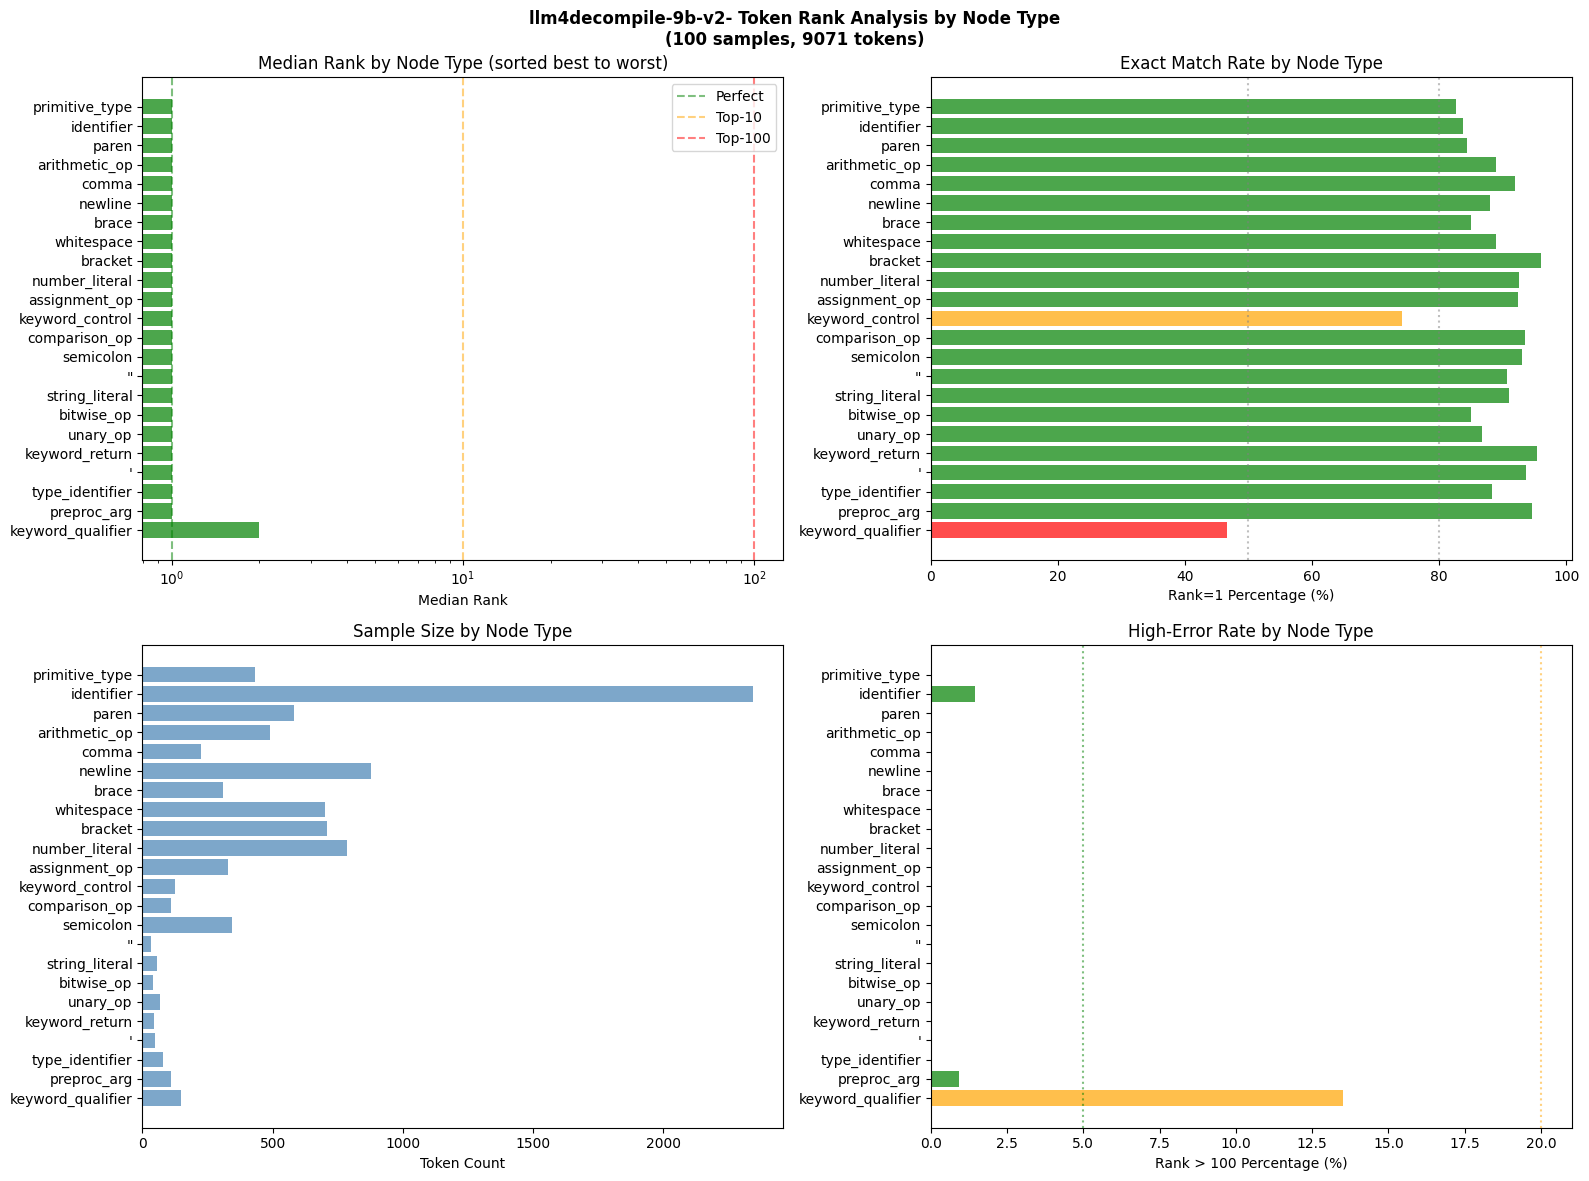

In [11]:
device = "cuda:0"
num_samples = 100
max_target_tokens = 128
# max_memory = {0: "20GiB",
#               1: "14GiB",
#               "cpu": "32GiB"}

output_dir = "/home/stu354543/outputs/tree_sitter_c3"
print("=" * 70)
print("TOKEN RANK ANALYSIS BY NODE TYPE - llm4decompile-9b-v2")
print("=" * 70)

# Initialize tree-sitter parser
print("\nInitializing tree-sitter C parser...")
parser = get_parser()

# Load model
print("\nLoading llm4decompile-9b-v2-...")
model_name = "LLM4Binary/llm4decompile-9b-v2"

tokenizer = AutoTokenizer.from_pretrained(model_name, trust_remote_code=True)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

model = AutoModelForCausalLM.from_pretrained(
    model_name,
    torch_dtype=torch.float16,
    device_map = device,
    # max_memory = max_memory,
    # offload_folder = "offload",
    # offload_state_dict = True,
    trust_remote_code=True,
)
model.eval()

vocab_size = model.config.vocab_size
print(f"Model loaded. Vocab size: {vocab_size:,}")

# Load dataset
print("\nLoading dataset...")
# dataset = load_dataset("LLM4Binary/decompile-eval", split="train")
samples = list(ds)
random.seed(42)
random.shuffle(samples)
samples = samples[:num_samples]
print(f"Using {num_samples} samples")

# Store ranks by node type
ranks_by_nodetype = defaultdict(list)
all_token_info = []

for sample_idx, item in enumerate(tqdm(samples, desc="Processing samples")):
    ghidra_code = item["c_code_unobf"]
    target_code = item["org_function"]

    prompt = f"# This is the assembly code:\n{ghidra_code}\n# What is the source code?\n"

    prompt_tokens = tokenizer.encode(prompt, add_special_tokens=True)
    target_tokens = tokenizer.encode(target_code, add_special_tokens=False)
    target_tokens = target_tokens[:max_target_tokens]

    # Build character-to-node mapping for target code
    try:
        char_to_node_map, tree = build_char_to_node_map(target_code, parser)
    except Exception:
        continue

    # Single forward pass
    full_input = prompt_tokens + target_tokens
    input_ids = torch.tensor([full_input], dtype=torch.long, device=device)

    with torch.no_grad():
        outputs = model(input_ids)
        start_idx = len(prompt_tokens) - 1
        end_idx = start_idx + len(target_tokens)
        target_logits = outputs.logits[0, start_idx:end_idx, :]

    # Vectorized rank computation
    target_tensor = torch.tensor(target_tokens, dtype=torch.long, device=device)
    probs = torch.softmax(target_logits, dim=-1)
    correct_probs = probs[torch.arange(len(target_tokens), device=device), target_tensor]
    ranks = 1 + (probs > correct_probs.unsqueeze(1)).sum(dim=1)
    sample_ranks = ranks.cpu().tolist()

    # Map each token to its node type
    char_position = 0
    for pos, (token_id, rank) in enumerate(zip(target_tokens, sample_ranks)):
        token_str = tokenizer.decode([token_id])
        node_type, new_char_position = map_token_to_nodetype(
            token_str, char_position, char_to_node_map, target_code
        )
        char_position = new_char_position
        ranks_by_nodetype[node_type].append(rank)
        all_token_info.append(
            {
                "sample_idx": sample_idx,
                "pos": pos,
                "token": token_str,
                "node_type": node_type,
                "rank": rank,
            }
        )

# Generate report
print("\n" + "=" * 70)
print("RANK STATISTICS BY NODE TYPE")
print("=" * 70)

nodetype_stats = []
for node_type, ranks in ranks_by_nodetype.items():
    ranks_arr = np.array(ranks)
    stats = {
        "node_type": node_type,
        "count": len(ranks),
        "median_rank": float(np.median(ranks_arr)),
        "mean_rank": float(np.mean(ranks_arr)),
        "rank_1_pct": float(100 * (ranks_arr == 1).mean()),
        "rank_le5_pct": float(100 * (ranks_arr <= 5).mean()),
        "rank_le10_pct": float(100 * (ranks_arr <= 10).mean()),
        "rank_gt100_pct": float(100 * (ranks_arr > 100).mean()),
        "rank_gt1000_pct": float(100 * (ranks_arr > 1000).mean()),
    }
    nodetype_stats.append(stats)

nodetype_stats.sort(key=lambda x: x["median_rank"])

print(
    f"\n{'Node Type':<25} {'Count':>8} {'Median':>8} {'Mean':>10} "
    f"{'Rank=1':>8} {'<=5':>6} {'<=10':>6} {'>100':>6} {'>1000':>6}"
)
print("-" * 95)

for stats in nodetype_stats:
    print(
        f"{stats['node_type']:<25} {stats['count']:>8} {stats['median_rank']:>8.1f} "
        f"{stats['mean_rank']:>10.1f} {stats['rank_1_pct']:>7.1f}% "
        f"{stats['rank_le5_pct']:>5.1f}% {stats['rank_le10_pct']:>5.1f}% "
        f"{stats['rank_gt100_pct']:>5.1f}% {stats['rank_gt1000_pct']:>5.1f}%"
    )

# Overall statistics
all_ranks = []
for ranks in ranks_by_nodetype.values():
    all_ranks.extend(ranks)
all_ranks = np.array(all_ranks)

print("\n" + "=" * 70)
print("OVERALL STATISTICS")
print("=" * 70)
print(f"Total token predictions: {len(all_ranks)}")
print(f"Overall median rank: {np.median(all_ranks):.1f}")
print(f"Overall mean rank: {np.mean(all_ranks):.1f}")
print(f"Rank 1 (exact match): {(all_ranks == 1).sum()} / {len(all_ranks)} ({100*(all_ranks == 1).mean():.1f}%)")
print(f"Rank <= 5: {(all_ranks <= 5).sum()} / {len(all_ranks)} ({100*(all_ranks <= 5).mean():.1f}%)")
print(f"Rank <= 10: {(all_ranks <= 10).sum()} / {len(all_ranks)} ({100*(all_ranks <= 10).mean():.1f}%)")
print(f"Rank > 100: {(all_ranks > 100).sum()} / {len(all_ranks)} ({100*(all_ranks > 100).mean():.1f}%)")
print(f"Rank > 1000: {(all_ranks > 1000).sum()} / {len(all_ranks)} ({100*(all_ranks > 1000).mean():.1f}%)")

# Insights
print("\n" + "=" * 70)
print("INSIGHTS")
print("=" * 70)

significant_types = [s for s in nodetype_stats if s["count"] >= 50]
if significant_types:
    best_types = significant_types[:5]
    worst_types = significant_types[-5:][::-1]

    print("\nBEST HANDLED NODE TYPES (lowest median rank, n>=50):")
    for i, stats in enumerate(best_types, 1):
        print(
            f"  {i}. {stats['node_type']}: median={stats['median_rank']:.1f}, "
            f"rank=1: {stats['rank_1_pct']:.1f}% (n={stats['count']})"
        )

    print("\nWORST HANDLED NODE TYPES (highest median rank, n>=50):")
    for i, stats in enumerate(worst_types, 1):
        print(
            f"  {i}. {stats['node_type']}: median={stats['median_rank']:.1f}, "
            f"rank=1: {stats['rank_1_pct']:.1f}% (n={stats['count']})"
        )

# --- Plots ---
print("\nGenerating plots...")

viz_stats = [s for s in nodetype_stats if s["count"] >= 20]
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Plot 1: Median rank by node type
ax1 = axes[0, 0]
node_types = [s["node_type"] for s in viz_stats]
median_ranks = [s["median_rank"] for s in viz_stats]
colors = ["green" if r <= 5 else "orange" if r <= 50 else "red" for r in median_ranks]
ax1.barh(node_types, median_ranks, color=colors, alpha=0.7)
ax1.set_xlabel("Median Rank")
ax1.set_title("Median Rank by Node Type (sorted best to worst)")
ax1.axvline(x=1, color="green", linestyle="--", alpha=0.5, label="Perfect")
ax1.axvline(x=10, color="orange", linestyle="--", alpha=0.5, label="Top-10")
ax1.axvline(x=100, color="red", linestyle="--", alpha=0.5, label="Top-100")
ax1.set_xscale("log")
ax1.legend()
ax1.invert_yaxis()

# Plot 2: Rank=1 percentage by node type
ax2 = axes[0, 1]
rank1_pcts = [s["rank_1_pct"] for s in viz_stats]
colors2 = ["green" if p >= 80 else "orange" if p >= 50 else "red" for p in rank1_pcts]
ax2.barh(node_types, rank1_pcts, color=colors2, alpha=0.7)
ax2.set_xlabel("Rank=1 Percentage (%)")
ax2.set_title("Exact Match Rate by Node Type")
ax2.axvline(x=50, color="gray", linestyle=":", alpha=0.5)
ax2.axvline(x=80, color="gray", linestyle=":", alpha=0.5)
ax2.invert_yaxis()

# Plot 3: Token count by node type
ax3 = axes[1, 0]
counts = [s["count"] for s in viz_stats]
ax3.barh(node_types, counts, color="steelblue", alpha=0.7)
ax3.set_xlabel("Token Count")
ax3.set_title("Sample Size by Node Type")
ax3.invert_yaxis()

# Plot 4: Error rate (rank > 100) by node type
ax4 = axes[1, 1]
error_pcts = [s["rank_gt100_pct"] for s in viz_stats]
colors4 = ["green" if p <= 5 else "orange" if p <= 20 else "red" for p in error_pcts]
ax4.barh(node_types, error_pcts, color=colors4, alpha=0.7)
ax4.set_xlabel("Rank > 100 Percentage (%)")
ax4.set_title("High-Error Rate by Node Type")
ax4.axvline(x=5, color="green", linestyle=":", alpha=0.5)
ax4.axvline(x=20, color="orange", linestyle=":", alpha=0.5)
ax4.invert_yaxis()

plt.suptitle(
    f"llm4decompile-9b-v2- Token Rank Analysis by Node Type\n"
    f"({num_samples} samples, {len(all_ranks)} tokens)",
    fontsize=12,
    fontweight="bold",
)
plt.tight_layout()

plot_path = Path(output_dir) / "token_rank_by_nodetype.png"
plt.savefig(plot_path, dpi=150, bbox_inches="tight")
print(f"\nPlot saved to: {plot_path}")

data_path = Path(output_dir) / "token_rank_by_nodetype.json"
output_data = {
    "nodetype_stats": nodetype_stats,
    "overall": {
        "total_tokens": len(all_ranks),
        "median_rank": float(np.median(all_ranks)),
        "mean_rank": float(np.mean(all_ranks)),
        "rank_1_pct": float(100 * (all_ranks == 1).mean()),
        "rank_le10_pct": float(100 * (all_ranks <= 10).mean()),
    },
}
with open(data_path, "w") as f:
    json.dump(output_data, f, indent=2)
print(f"Data saved to: {data_path}")